# Doomsday Sentinel: AI-Powered Deepfake Forensics
## Notebook 03: Deep Learning Forensic Model Training

Trains a transfer learning architecture (EfficientNet-B0) with warmup backbone freezing, AdamW optimizer, CosineAnnealingLR scheduling, mixed precision (AMP), and early stopping.

In [1]:
import os
import sys
import yaml
import torch
import pandas as pd
import matplotlib.pyplot as plt

os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
from src.data.dataset import create_dataloaders
from src.models.classifier import build_model
from src.training.trainer import Trainer

### 1. Verify Compute Environment

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using compute device: {device}')
if device == 'cuda':
    print(torch.cuda.get_device_name(0))

Using compute device: cuda
NVIDIA RTX A2000 12GB


### 2. Prepare Leakage-Resistant DataLoaders

In [3]:
train_df = pd.read_csv('data/manifests/train_manifest.csv')
val_df = pd.read_csv('data/manifests/val_manifest.csv')
test_df = pd.read_csv('data/manifests/test_manifest.csv')

loaders = create_dataloaders(
    train_manifest=train_df,
    val_manifest=val_df,
    test_manifest=test_df,
    batch_size=32,
    num_workers=0
)
print(f'Train Batches: {len(loaders["train"])}, Val Batches: {len(loaders["val"])}')

Train Batches: 27, Val Batches: 6


### 3. Initialize EfficientNet-B0 with Forensic Head

In [4]:
model = build_model(architecture='efficientnet_b0', pretrained=True, device=device)
print(model)

DeepfakeClassifier(
  (backbone): EfficientNet(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): Sequential(
        (0): MBConv(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
              (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              (2): SiLU(inplace=True)
            )
            (1): SqueezeExcitation(
              (avgpool): AdaptiveAvgPool2d(output_size=1)
              (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
              (activation): SiLU(inplace=True)
              

### 4. Review Saved Training History

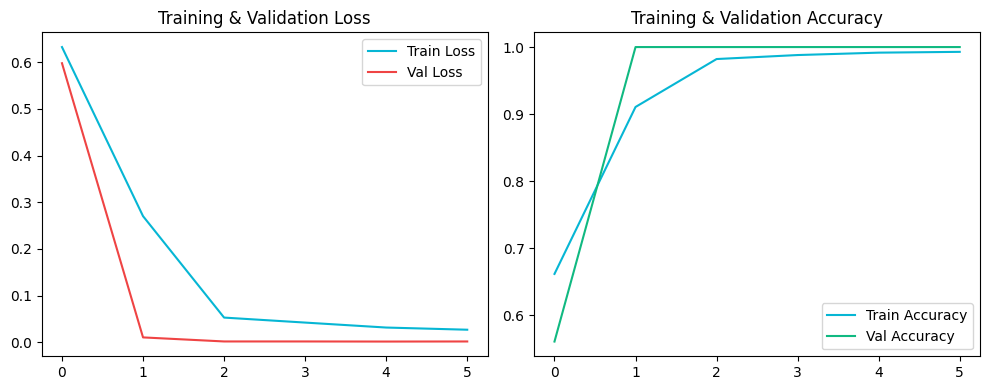

In [5]:
import json
with open('reports/experiment_summary.json', 'r') as f:
    summary = json.load(f)
history = summary['history']

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss', color='#06b6d4')
plt.plot(history['val_loss'], label='Val Loss', color='#ef4444')
plt.title('Training & Validation Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Accuracy', color='#06b6d4')
plt.plot(history['val_acc'], label='Val Accuracy', color='#10b981')
plt.title('Training & Validation Accuracy')
plt.legend()
plt.tight_layout()
plt.show()